In [1]:
#Shishir Khanal
#Aug 29, 2026
#Actor Critic Algorithm using Twin Delayed Deep Deterministic Policy Gradient

In [2]:
import os
import pygame
import torch as T
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np
import gym

pygame-ce 2.5.7 (SDL 2.32.10, Python 3.12.7)


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


In [3]:
class CriticNetwork(nn.Module):
    def __init__(self, beta, input_dims, fc1_dims, fc2_dims, n_actions, name, chkpt_dir='tmp/td3'):
        super(CriticNetwork, self).__init__()
        self.input_dims = input_dims
        self.fc1_dims = fc1_dims
        self.fc2_dims = fc2_dims
        self.n_actions = n_actions
        self.name = name
        self.checkpoint_dir = chkpt_dir
        self.checkpoint_file = os.path.join(self.checkpoint_dir, name+'_td3')

        #This might fail if env has 2D state representation
        self.fc1 = nn.Linear(self.input_dims[0] + n_actions, self.fc1_dims)
        self.fc2 = nn.Linear(self.fc1_dims, self.fc2_dims)
        self.q1 = nn.Linear(self.fc2_dims, 1)

        self.optimizer = optim.Adam(self.parameters(), lr=beta)
        self.device = T.device('cuda:0' if T.cuda.is_available() else 'cpu')
        self.to(self.device)

    def forward(self, state, action):
        q1_action_value = self.fc1(T.cat([state, action], dim=1))
        q1_action_value = F.relu(q1_action_value)
        q1_action_value = self.fc2(q1_action_value)
        q1_action_value = F.relu(q1_action_value)

        q1 = self.q1(q1_action_value)

        return q1

    def save_checkpoint(self):
        print('Saving checkpoint...')
        T.save(self.state_dict(), self.checkpoint_file)

    def load_checkpoint(self):
        self.load_state_dict(T.load(self.checkpoint_file))    

In [4]:
class ActorNetwork(nn.Module):
    def __init__(self, alpha, input_dims, fc1_dims, fc2_dims, n_actions, name, chkpt_dir='tmp/td3'):
        super(ActorNetwork, self).__init__()
        self.input_dims = input_dims
        self.fc1_dims = fc1_dims
        self.fc2_dims = fc2_dims
        self.n_actions = n_actions
        self.name = name
        self.checkpoint_dir = chkpt_dir
        self.checkpoint_file = os.path.join(self.checkpoint_dir, name+'_td3')

        self.fc1 = nn.Linear(*self.input_dims, self.fc1_dims)
        self.fc2 = nn.Linear(self.fc1_dims, self.fc2_dims)
        self.mu = nn.Linear(self.fc2_dims, self.n_actions)

        self.optimizer = optim.Adam(self.parameters(), lr=alpha)
        self.device = T.device('cuda:0' if T.cuda.is_available() else 'cpu')
        self.to(self.device)

    def forward(self, state):
        prob = self.fc1(state)
        prob = F.relu(prob)
        prob = self.fc2(prob)
        prob = F.relu(prob)
        prob = T.tanh(self.mu(prob))   # if action > +/- 1, multiply by max action
        return prob

    def save_checkpoint(self):
        print('Saving checkpoint...')
        T.save(self.state_dict(), self.checkpoint_file)

    def load_checkpoint(self):
        print('Loading checkpoint...')
        self.load_state_dict(T.load(self.checkpoint_file))

In [5]:
#Replay buffer: Fixed size, overwrites early memories with new ones
class ReplayBuffer():
    def __init__(self, max_size, input_shape, n_actions):
        self.mem_size = max_size
        self.mem_cntr = 0
        self.state_memory = np.zeros((self.mem_size, *input_shape)) #'*' means unpack list of elements
        self.new_state_memory = np.zeros((self.mem_size, *input_shape))
        self.action_memory = np.zeros((self.mem_size, n_actions)) #For lunar lander 4 element
        self.reward_memory = np.zeros(self.mem_size)
        self.terminal_memory = np.zeros(self.mem_size, dtype=bool) #mask for setting critique values for new states to 0

    def store_transition(self, state, action, reward, state_, done):
        index = self.mem_cntr % self.mem_size
        self.state_memory[index] = state
        self.action_memory[index] = action
        self.reward_memory[index] = reward
        self.new_state_memory[index] = state_
        self.terminal_memory[index] = done
        self.mem_cntr += 1

    def sample_buffer(self, batch_size):
        max_mem = min(self.mem_cntr, self.mem_size)
        batch = np.random.choice(max_mem, batch_size)
        states = self.state_memory[batch] 
        actions = self.action_memory[batch] 
        rewards = self.reward_memory[batch]
        states_ = self.new_state_memory[batch]
        dones = self.terminal_memory[batch]

        return states, actions, rewards, states_, dones 

In [6]:
#Exploration Noise Gaussion(0, 0.1)
#Actor and 2 critic networks, target networs: Hyperparams, Replay memory

class Agent(nn.Module):
    def __init__(self, alpha, beta, input_dims, tau, env, gamma=0.99, 
                 update_actor_interval=2, warmup=1000, n_actions=2, 
                 max_size=1000000, layer1_size=400, layer2_size=300, 
                 batch_size=100, noise=0.1):
        super(Agent, self).__init__()
        self.gamma = gamma
        self.tau = tau
        self.env = env
        self.max_action = self.env.action_space.high
        self.min_action = self.env.action_space.low
        self.memory = ReplayBuffer(max_size, input_dims, n_actions)
        self.batch_size = batch_size
        self.learn_step_counter = 0
        self.time_step = 0
        self.warmup = warmup
        self.n_actions = n_actions
        self.update_actor_iter = update_actor_interval

        self.actor = ActorNetwork(alpha, input_dims, layer1_size, layer2_size, n_actions=n_actions, name='actor')
        self.critic_1 = CriticNetwork(beta, input_dims, layer1_size, layer2_size, n_actions=n_actions, name='critic_1')
        self.critic_2 = CriticNetwork(beta, input_dims, layer1_size, layer2_size, n_actions=n_actions, name='critic_2')

        self.target_actor = ActorNetwork(alpha, input_dims, layer1_size, layer2_size, n_actions=n_actions, name='target_actor')
        self.target_critic_1 = CriticNetwork(beta, input_dims, layer1_size, layer2_size, n_actions=n_actions, name='target_critic_1')
        self.target_critic_2 = CriticNetwork(beta, input_dims, layer1_size, layer2_size, n_actions=n_actions, name='target_critic_2')
        
        self.noise = noise
        self.update_network_parameters(tau=1)
        
    def choose_action(self, observation):
        if self.time_step < self.warmup:
            mu = T.tensor(np.random.normal(scale=self.noise, size=(self.n_actions,)), dtype=T.float32, device=self.actor.device)
        else:
            state = T.tensor(observation, dtype=T.float).to(self.actor.device)
            mu = self.actor.forward(state).to(self.actor.device)
        mu_prime = mu + T.tensor(np.random.normal(scale=self.noise), dtype=T.float).to(self.actor.device)
        mu_prime = T.clamp(mu_prime, self.min_action[0], self.max_action[0])
        self.time_step += 1
        return mu_prime.cpu().detach().numpy()

    def remember(self, state, action, reward, new_state, done):
        self.memory. store_transition(state, action, reward, new_state, done)

    def learn(self):
        #y=r + γ*min(i=1,2) Q(θ'i)(s\, a~)
        #a~ = π(ϕ')(s') + clip(N(0, 0.2), -0.5, 0.5)
        # Critic Loss: L = (1/N)Σ(y - Q(θi)(s,a))^2
        # Actor Loss: ∇(ϕ)J(ϕ) = (1/N) * Σ(ϕ)Q(θ1)(s,a)|a=π(ϕ)(s)
        if self.memory.mem_cntr < self.batch_size:
            return

        state, action, reward, new_state, done = self.memory.sample_buffer(self.batch_size)
        reward = T.tensor(reward, dtype=T.float).to(self.critic_1.device)
        done = T.tensor(done).to(self.critic_1.device)
        state_ = T.tensor(new_state, dtype=T.float).to(self.critic_1.device)
        state = T.tensor(state, dtype=T.float).to(self.critic_1.device)
        action = T.tensor(action, dtype=T.float).to(self.critic_1.device)

        target_actions = self.target_actor.forward(state_)
        target_actions = target_actions + T.clamp(T.tensor(np.random.normal(scale=0.2)), -0.5, 0.5)
        #Might break if minmax are not symmetrical(eg -2, +1)
        target_actions = T.clamp(target_actions, self.min_action[0], self.max_action[0])

        q1_ = self.target_critic_1.forward(state_, target_actions)
        q2_ = self.target_critic_2.forward(state_, target_actions)

        q1 = self.critic_1.forward(state, action)
        q2 = self.critic_2.forward(state, action)

        q1_[done] = 0.0
        q2_[done] = 0.0

        q1_ = q1_.view(-1)
        q2_ = q2_.view(-1)

        critic_value_ = T.min(q1_, q2_)
        
        target = reward + self.gamma * critic_value_
        target = target.view(self.batch_size, 1)

        self.critic_1.optimizer.zero_grad()
        self.critic_2.optimizer.zero_grad()

        q1_loss = F.mse_loss(target, q1)
        q2_loss = F.mse_loss(target, q2)
        critic_loss = q1_loss + q2_loss
        critic_loss.backward()

        self.critic_1.optimizer.step()
        self.critic_2.optimizer.step()

        self.learn_step_counter += 1

        if self.learn_step_counter % self.update_actor_iter != 0:
            return

        self.actor.optimizer.zero_grad()
        actor_q1_loss = self.critic_1.forward(state, self.actor.forward(state))
        actor_loss = -T.mean(actor_q1_loss)
        actor_loss.backward()
        self.actor.optimizer.step()
        self.update_network_parameters()

    def update_network_parameters(self, tau=None):
        #Network Copy
        #θi' <-- τθi + (1 - τ) * θi'
        #ϕ' <-- τϕ + (1 - τ) * ϕ'
        if tau == None:
            tau = self.tau

        actor_params = self.actor.named_parameters()
        critic_1_params = self.critic_1.named_parameters()
        critic_2_params = self.critic_2.named_parameters()
        target_actor_params = self.target_actor.named_parameters()
        target_critic_1_params = self.target_critic_1.named_parameters()
        target_critic_2_params = self.target_critic_2.named_parameters()

        critic_1_state_dict = dict(critic_1_params)
        critic_2_state_dict = dict(critic_2_params)
        actor_state_dict = dict(actor_params)
        target_actor_state_dict = dict(target_actor_params)
        target_critic_1_state_dict = dict(target_critic_1_params)
        target_critic_2_state_dict = dict(target_critic_2_params)

        for name in critic_1_state_dict:
            critic_1_state_dict[name] = tau * critic_1_state_dict[name].clone() + (1-tau) * target_critic_1_state_dict[name].clone()

        for name in critic_2_state_dict:
            critic_2_state_dict[name] = tau * critic_2_state_dict[name].clone() + (1-tau) * target_critic_2_state_dict[name].clone()
            
        for name in actor_state_dict:
            actor_state_dict[name] = tau * actor_state_dict[name].clone() + (1-tau) * target_actor_state_dict[name].clone()

        self.target_critic_1.load_state_dict(critic_1_state_dict)
        self.target_critic_2.load_state_dict(critic_2_state_dict)
        self.target_actor.load_state_dict(actor_state_dict)

    def save_models(self):
        self.actor.save_checkpoint()
        self.target_actor.save_checkpoint()
        self.critic_1.save_checkpoint()
        self.critic_2.save_checkpoint()
        self.target_critic_1.save_checkpoint()
        self.target_critic_2.save_checkpoint()

    def load_models(self):
        self.actor.load_checkpoint()
        self.target_actor.load_checkpoint()
        self.critic_1.load_checkpoint()
        self.critic_2.load_checkpoint()
        self.target_critic_1.load_checkpoint()
        self.target_critic_2.load_checkpoint()

In [7]:
def plot_learning_curve(scores, x, figure_file):
    running_avg = np.zeros(len(scores))
    for i in range(len(running_avg)):
        running_avg[i] = np.mean(scores[max(0, i-100):(i+1)])
    plt.plot(x, running_avg)
    plt.title('Running average of previous 100 scores')
    plt.show()
    plt.savefig(figure_file)

In [8]:
if __name__ == '__main__':
    render_every = 50  # set to 1 to watch every episode (slow)
    env = gym.make('BipedalWalker-v3', render_mode="rgb_array")
    agent = Agent(alpha=0.001, beta=0.001, input_dims=env.observation_space.shape,
                  tau=0.005, env=env, batch_size=100, layer1_size=400, layer2_size=300,
                  n_actions=env.action_space.shape[0])
    n_games = 3000
    filename = 'Walker2d_' + str(n_games) + '.png'
    figure_file = 'plots/' + filename

    best_score = env.reward_range[0]
    score_history = []
    #agent.load_models()

    pygame.init()
    env.reset()  # must reset before the first render() call
    frame = env.render()  # grab one frame to get dimensions
    window = pygame.display.set_mode((frame.shape[1], frame.shape[0]))
    pygame.display.set_caption('BipedalWalker - TD3 Agent')
    episode_font = pygame.font.SysFont('Arial', 24)
    clock = pygame.time.Clock()

    for i in range(n_games):
        done = False
        observation, info = env.reset()
        score = 0
        render_this_episode = (i % render_every == 0)

        while not done:
            action = agent.choose_action(observation)
            observation_, reward, truncated, terminated, info = env.step(action)
            done = truncated or terminated
            agent.remember(observation, action, reward, observation_, done)
            agent.learn()
            score += reward
            observation = observation_  # current state = new state

            if render_this_episode:
                pygame.event.pump()  # keep OS from thinking window is frozen
                frame = env.render()  # returns an (H, W, 3) rgb array
                surf = pygame.surfarray.make_surface(frame.swapaxes(0, 1))
                window.blit(surf, (0, 0))

                text_surface = episode_font.render(
                    f'TD3 Ep: {i + 1}/{n_games}', True, (0, 0, 0)
                )
                window.blit(text_surface, (10, 10))

                pygame.display.flip()
                clock.tick(60)

        score_history.append(score)
        avg_score = np.mean(score_history[-100:])

        if avg_score > best_score:
            best_score = avg_score
            agent.save_models()

        print('episode', i, 'score %.2f' % score, 'trailing 100 games average score %.3f' % avg_score)

    pygame.quit()
    x = [i + 1 for i in range(len(score_history))]

/home/shishir/anaconda3/lib/python3.12/site-packages/torch/cuda/__init__.py:182: UserWarning: CUDA initialization: CUDA unknown error - this may be due to an incorrectly set up environment, e.g. changing env variable CUDA_VISIBLE_DEVICES after program start. Setting the available devices to be zero. (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0
/home/shishir/anaconda3/lib/python3.12/site-packages/gym/utils/passive_env_checker.py:233: DeprecationWarning: `np.bool8` is a deprecated alias for `np.bool_`.  (Deprecated NumPy 1.24)
  if not isinstance(terminated, (bool, np.bool8)):


Saving checkpoint...
Saving checkpoint...
Saving checkpoint...
Saving checkpoint...
Saving checkpoint...
Saving checkpoint...
episode 0 score -95.30 trailing 100 games average score -95.299
Saving checkpoint...
Saving checkpoint...
Saving checkpoint...
Saving checkpoint...
Saving checkpoint...
Saving checkpoint...
episode 1 score -93.85 trailing 100 games average score -94.574
episode 2 score -96.26 trailing 100 games average score -95.135
episode 3 score -93.83 trailing 100 games average score -94.809
episode 4 score -94.66 trailing 100 games average score -94.779
episode 5 score -114.86 trailing 100 games average score -98.127
episode 6 score -94.81 trailing 100 games average score -97.653
episode 7 score -95.42 trailing 100 games average score -97.374
episode 8 score -120.51 trailing 100 games average score -99.945
episode 9 score -118.46 trailing 100 games average score -101.796
episode 10 score -119.03 trailing 100 games average score -103.363
episode 11 score -118.19 trailing 100

In [9]:
# if __name__ == '__main__':
#     env = gym.make('BipedalWalker-v3', render_mode="human")
#     #env = gym.make('BipedalWalker-v3')
#     agent = Agent(alpha=0.001, beta=0.001, input_dims=env.observation_space.shape, 
#                   tau=0.005, env=env, batch_size=100, layer1_size=400, layer2_size=300, 
#                   n_actions=env.action_space.shape[0])
#     n_games = 1500
#     filename = 'Walker2d_' + str(n_games) + '.png'
#     figure_file = 'plots/'+filename
    
#     best_score = env.reward_range[0]
#     score_history = []
#     #agent.load_models()
    
#     for i in range(n_games):
#         done = False
#         observation, info = env.reset()
#         score = 0
#         while not done:
#             action = agent.choose_action(observation)
#             observation_, reward, truncated, terminated, info = env.step(action)
#             done = truncated or terminated
#             agent.remember(observation, action, reward, observation_, done)
#             agent.learn()
#             score += reward
#             observation = observation_ #current state = new state
#         score_history.append(score)
#         avg_score = np.mean(score_history[-100:])
#         env.render()
#         if avg_score > best_score:
#             best_score = avg_score
#             agent.save_models()
#         print('episode', i, 'score %.2f' % score, 'trailing 100 games average score %.3f' % avg_score)

#     x = [i+1 for i in range(len(score_history))]

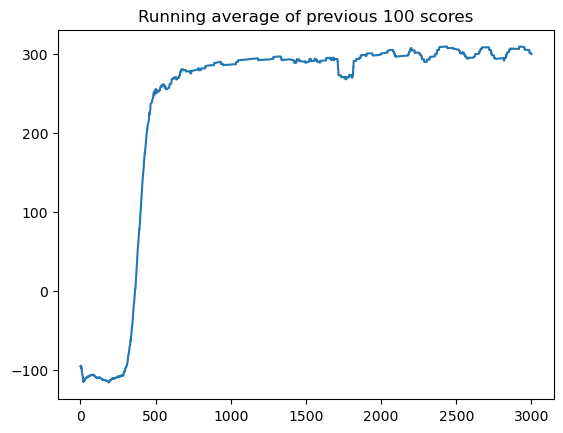

<Figure size 640x480 with 0 Axes>

In [10]:
import matplotlib.pyplot as plt

plot_learning_curve(scores=score_history, x=x, figure_file=figure_file)